# AI Generated Lineup with No Reference Faces
    Raw descriptioin vs OpenAI prompt processing

- **Raw description**: prompt → gpt-image。
- **prompt processing**: prompt → OpenAI preprocessing → gpt-image。

In [1]:
from pathlib import Path
from uuid import uuid4
import random
import sys
from PIL import Image as PILImage
from IPython.display import Image as DisplayImage, display
from pyWitnessAI import FaceGenerator, LineupBuilder, RawDescriptionParser, image_paths

DESCRIPTION = "A man in his twenties, short hair, no beard, slim build, with prominent eyebrows and eyes."

PROMPT_PROCESSING_MODEL = "gpt-6-sol"
N = 6
IMAGE_SIZE = "1024x1024"
QUALITY = "high"
OUTPUT_FORMAT = "png"
LINEUP_SEED = 81
OUTPUT_ROOT = Path("D:/PhD/Studies/FaceGenerate/Below Average/White/newStudy_V1_test_M1/6-sol")

## API key

In [2]:
import os
from getpass import getpass

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")

OpenAI API key:  ········


## Two sets of FaceGenerator

In [3]:
common = dict(
    generator_backend="openai",
    description=DESCRIPTION,
    parser=RawDescriptionParser(lowercase=False),
    n=N,
    size=IMAGE_SIZE,
    quality=QUALITY,
    output_format=OUTPUT_FORMAT,
    write_manifest=True,
)
direct_generator = FaceGenerator(
    output_dir=OUTPUT_ROOT / "without_processing",
    conversation_model=None,
    **common,
)
processed_generator = FaceGenerator(
    output_dir=OUTPUT_ROOT / "with_processing",
    conversation_model=PROMPT_PROCESSING_MODEL,
    **common,
)

base_prompts = direct_generator.generation_prompts()
assert base_prompts == processed_generator.generation_prompts()
print("base prompt：\n" + base_prompts[0])

base prompt：
Make a photo of an under average-looking man, with facial features and hair style completely different from each other, but matching the following description: A man in his twenties, short hair, no beard, slim build, with prominent eyebrows and eyes. Make it an image portrait, only from shoulders above. Make the background gray. The people should be looking at the camera with frontal face. Do not emphasize or depict body actions, hand placement, or clothing interactions.


## Condition A：No prompt processing


prompt：
Make a photo of an under average-looking man, with facial features and hair style completely different from each other, but matching the following description: A man in his twenties, short hair, no beard, slim build, with prominent eyebrows and eyes. Make it an image portrait, only from shoulders above. Make the background gray. The people should be looking at the camera with frontal face. Do not emphasize or depict body actions, hand placement, or clothing interactions.



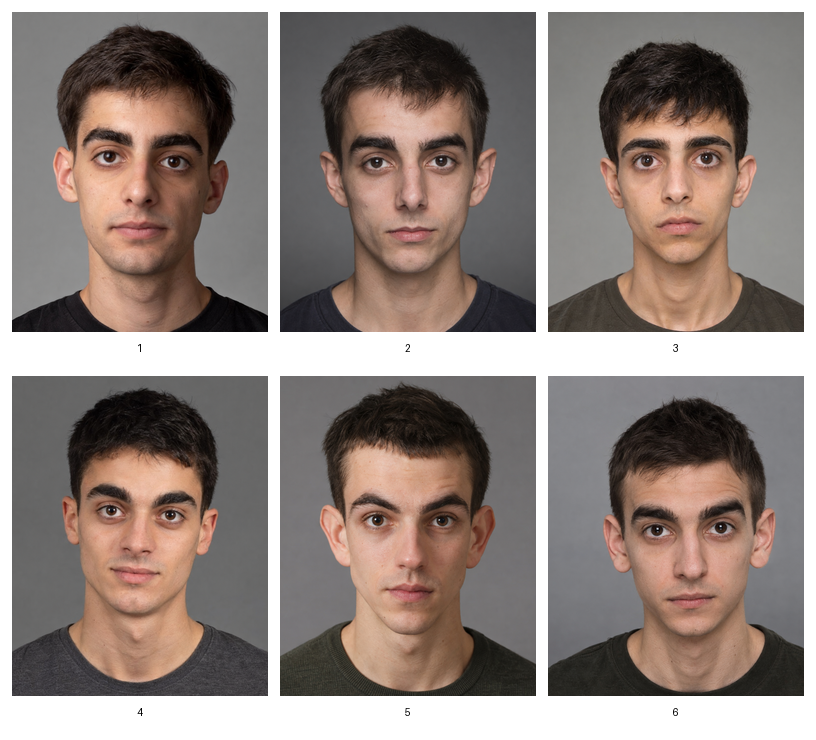

In [13]:
direct_faces = direct_generator.generate()
assert [face.prompt for face in direct_faces] == base_prompts
for prompt in dict.fromkeys(face.prompt for face in direct_faces):
    print("prompt：\n" + prompt + "\n")

direct_lineup = LineupBuilder(
    suspect=None,
    filler_pool=direct_generator.to_manifest(),
    size=N, rows=2, target="absent", order="random", seed=LINEUP_SEED,
).build()
direct_lineup = direct_lineup.standardize(standardizer)
_d = direct_lineup.show()
direct_lineup.render().save(direct_generator.output_dir / "TA.png")

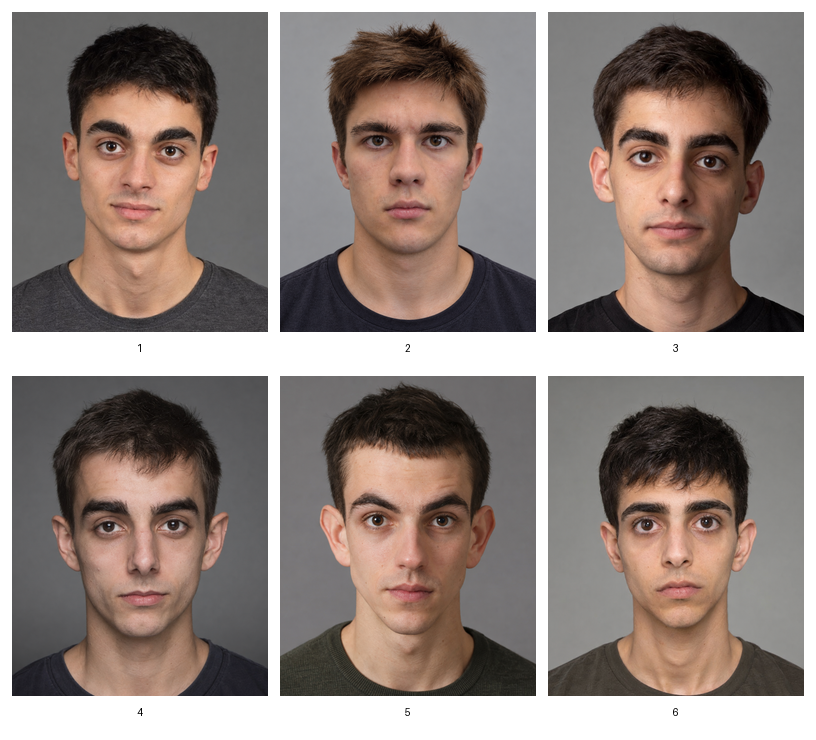

In [15]:
direct_lineup = LineupBuilder(
    suspect="D:/PhD/Studies/FaceGenerate/perp_refer_to_AI_generated_image.png",
    filler_pool=direct_generator.to_manifest(),
    size=N, rows=2, target="absent", order="random", seed=21,
).build()
direct_lineup = direct_lineup.standardize(standardizer)
_d = direct_lineup.show()
direct_lineup.render().save(direct_generator.output_dir / "TA.png")

## Condition B：With prompt processing

In [4]:
processed_prompts = processed_generator.generation_prompts(process=True)
for i, prompt in enumerate(processed_prompts, 1):
    print(f"Filler {i} prompt processed：\n{prompt}\n")

Filler 1 prompt processed：
An unretouched candid photograph of an adult in an everyday street setting. A man in his twenties, short hair, no beard, slim build, with prominent eyebrows and eyes.

Age 21, with an oval face, a softly tapered chin, a straight narrow nose, full lower lip, warm beige complexion, dark brown irises, and close-cropped black curls.

Make it an image portrait, only from shoulders above. Make the background gray. The people should be looking at the camera with frontal face. Do not emphasize or depict body actions, hand placement, or clothing interactions.

Filler 2 prompt processed：
An unretouched candid photograph of an adult in an everyday street setting. A man in his twenties, short hair, no beard, slim build, with prominent eyebrows and eyes.

Age 24, with a broad square face, an angular jaw, a wide nose with a rounded tip, thin lips, deep brown complexion, brown irises, and a short, tightly coiled dark-brown high-top.

Make it an image portrait, only from sho

In [6]:
processed_faces = processed_generator.generate()

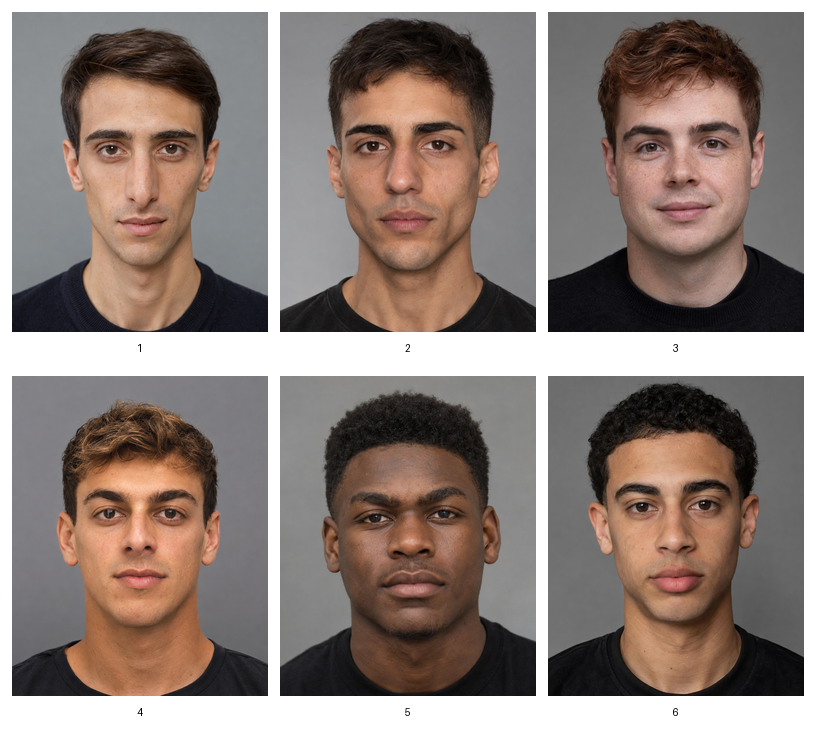

In [7]:
processed_lineup = LineupBuilder(
    suspect=None,
    filler_pool=processed_generator.to_manifest(),
    size=N, rows=2, target="absent", order="random", seed=LINEUP_SEED,
).build()
from pyWitnessAI import FaceStandardizer
standardizer = FaceStandardizer()
lineup = processed_lineup.standardize(standardizer)
_ = lineup.show()
lineup.render().save(processed_generator.output_dir / "TA.png")

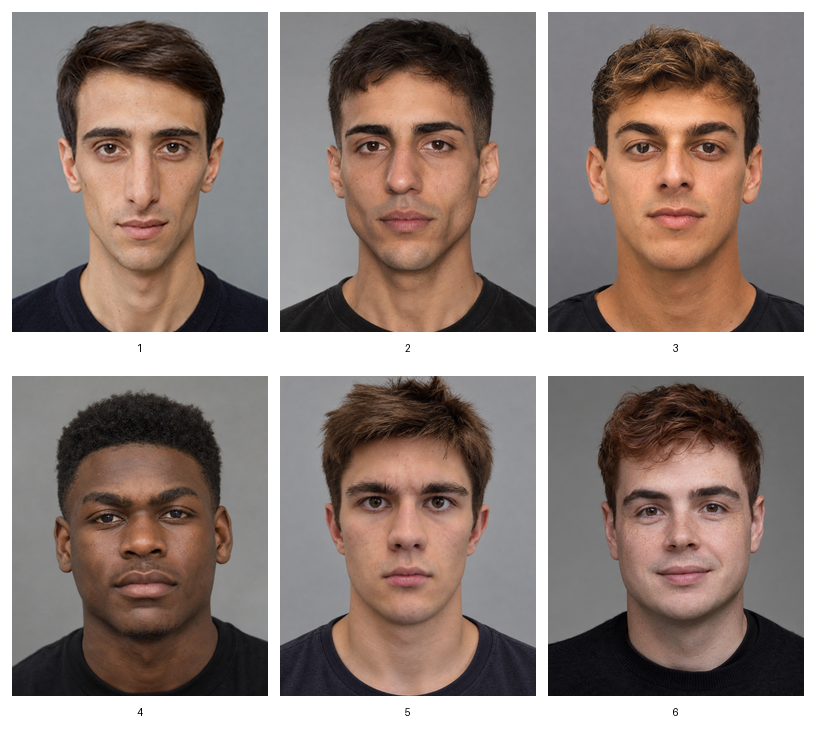

In [8]:
processed_lineup = LineupBuilder(
    suspect="D:/PhD/Studies/FaceGenerate/perp_refer_to_AI_generated_image.png",
    filler_pool=processed_generator.to_manifest(),
    size=N, rows=2, target="absent", order="random", seed=LINEUP_SEED,
).build()
from pyWitnessAI import FaceStandardizer
standardizer = FaceStandardizer(size=(256, 320), alignment="center", eye_distance=0.25, fill_canvas=True,)
lineup = processed_lineup.standardize(standardizer)
_ = lineup.show()
lineup.render().save(processed_generator.output_dir / "TA.png")

## Origin base prompt
    Make a photo of a under average-looking man ...

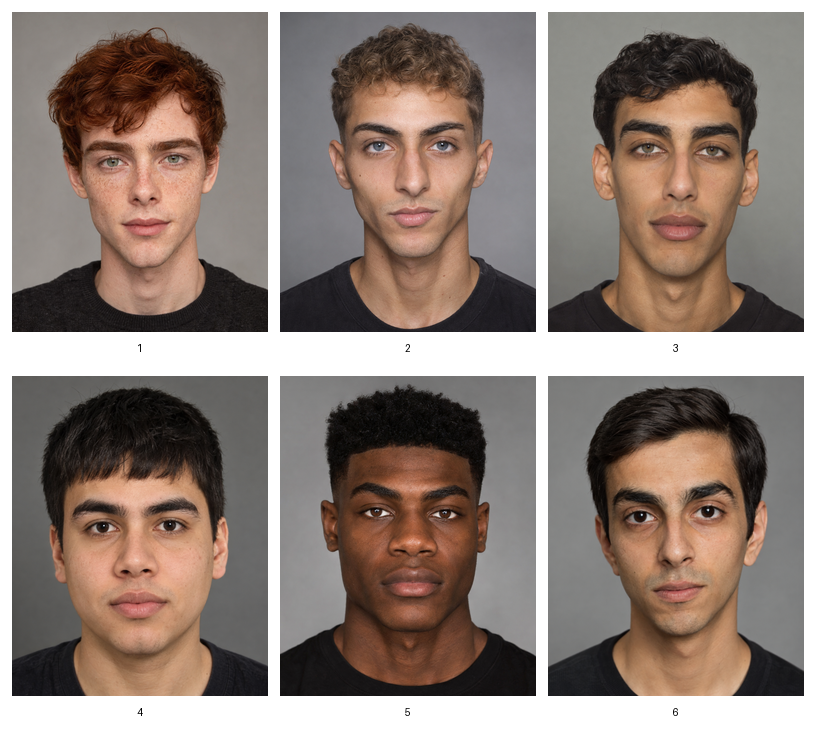

In [6]:
processed_lineup = LineupBuilder(
    suspect=None,
    filler_pool=processed_generator.to_manifest(),
    size=N, rows=2, target="absent", order="random", seed=LINEUP_SEED,
).build()
from pyWitnessAI import FaceStandardizer
standardizer = FaceStandardizer()
lineup = processed_lineup.standardize(standardizer)
_ = lineup.show()
lineup.render().save(processed_generator.output_dir / "TA.png")

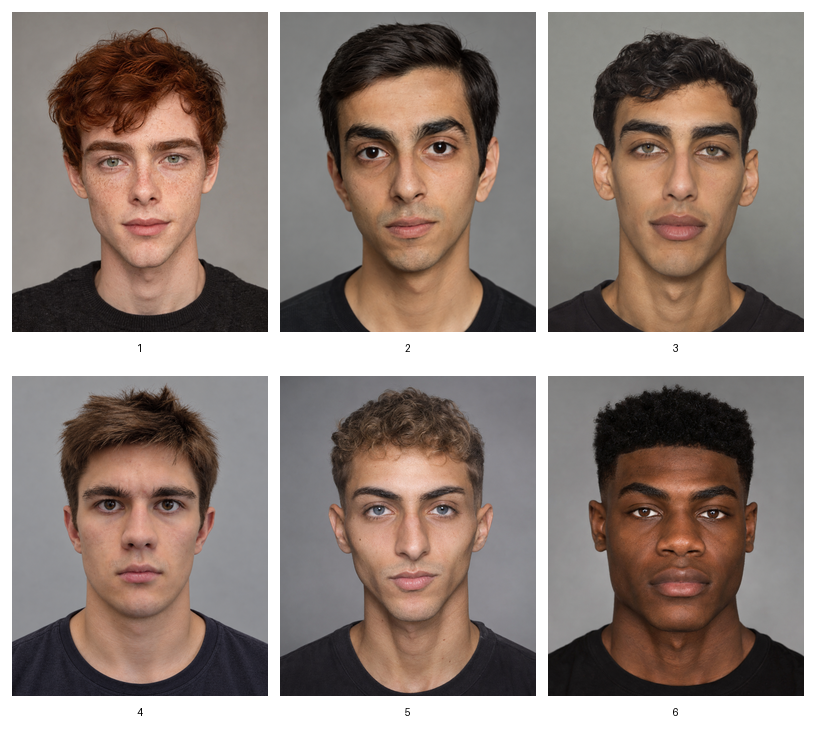

In [9]:
processed_lineup = LineupBuilder(
    suspect="D:/PhD/Studies/FaceGenerate/perp_refer_to_AI_generated_image.png",
    filler_pool=processed_generator.to_manifest(),
    size=N, rows=2, target="absent", order="random", seed=66,
).build()
from pyWitnessAI import FaceStandardizer
standardizer = FaceStandardizer(alignment="center", eye_distance=0.20, fill_canvas=True)
lineup = processed_lineup.standardize(standardizer)
_ = lineup.show()
lineup.render().save(processed_generator.output_dir / "TP.png")